# Pack 4-D
Code to pack images in data into a .npy format

In [1]:
import os
from os.path import splitext, isfile, join
import glob

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
def load_image(filename: str) -> Image:
    """
    Loads a file in PIL Image format.
    :param filename: the filepath to load
    :return: the image in PIL format
    """
    ext = splitext(filename)[1]
    if ext == '.npy':
        return Image.fromarray(np.load(filename))
    elif ext in ['.pt', '.pth']:
        return Image.fromarray(torch.load(filename).numpy())
    else:
        return Image.open(filename)

In [3]:
def load_directory(folder: str) -> [np.array]:
    """
    Given a folder directory containing masks, load all of the masks in order and 
    create a volume from them.
    :param folder: the folder path to load from
    :return: returns a list of ordered volumes of the segmentation masks
    """
    # Check if there are any files mistakenly left in the base directory.
    directory_contents = os.listdir(folder)
    for c in directory_contents:
        if os.path.isfile(folder + "/" + c):
            raise Exception("Error! Do not have any masks in the base directory. \
                             Move them into individual folders for each frame! \
                             If you are working with a static set of masks, move them into one folder!")

    # Sort the folders in alphabetical order for each frame
    folders = sorted([name for name in os.listdir(folder) if os.path.isdir(os.path.join(folder, name))])
    volume_list = []

    # Load up each segmentation volume and save it to a list of volumes. Each index in volume_list is a frame.
    for f in folders:
        curr_path = folder + "/" + f + "/*"
        files = sorted(glob.glob(curr_path))
        segmentations = np.array([np.asarray(load_image(img)) for img in files])
        volume_list.append(segmentations)
    return volume_list

In [9]:
filepath = "data/segmentations/patient001_4d_lv/"
output_path = "data/npy/lv.npy"

# Volume indexing:
# [frame : slice z : y : x]
volumes = np.array(load_directory(filepath))
volumes = np.where(volumes != 0, 1, 0).astype(bool)
with open(output_path, 'wb') as f:
    np.save(f, volumes)

In [5]:
volumes.dtype

dtype('bool')

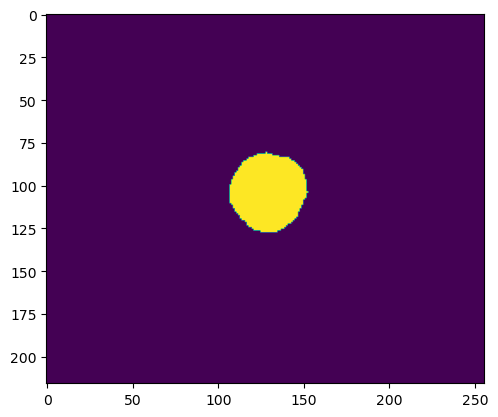

In [6]:
plt.imshow(volumes[0][5])

In [7]:
volumes[0].shape

(10, 216, 256)